This notebook is a simple demo of what Onion can do.

In [1]:
# imports
import os

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from datasets import load_dataset

import onion

In [2]:
# we write a function to produce a CNN of arbitrary dimensions
# this looks complicated, but it has to know when to add regularization, batch norm, dropout, etc

def conv_net(
    inp_shape: list[int],
    n_classes: int,
    conv_dims: list[tuple[int, int, int]],
    fc_dims: list[int],
    conv_reg: float = 0.0,
    fc_reg: float = 0.0,
    conv_dropout_p: float = 0.0,
    fc_dropout_p: float = 0.0,
    conv_batchnorm: bool = False,
    fc_batchnorm: bool = False,
    activation: type = onion.ReLU,
) -> onion.DAGModel:
    name_counter = {}
    input = a = onion.node(onion.Parameter("input", inp_shape), name_counter=name_counter)
    if len(inp_shape) == 2:
        inp_shape = *inp_shape, 1
        a = onion.node(onion.Reshape("Reshape", (-1, *inp_shape)), name_counter=name_counter, a=a)
    losses = []
    for n_channels, kernel_size, pad, pool_size in conv_dims:
        prev_n_channels = inp_shape[-1]
        a = onion.node(
            onion.Convolution("Conv", pad=pad),
            losses,
            name_counter=name_counter, 
            activation=activation(),
            X=a,
            K=(((kernel_size, kernel_size, prev_n_channels, n_channels), 0.0, (kernel_size * kernel_size * prev_n_channels) ** -0.5), conv_reg),
            b=((n_channels, 0.0, 0.0), 0.0),
        )
        inp_shape = [xd + 2 * pad - kernel_size + 1 for xd in inp_shape[:-1]] + [n_channels]
        if pool_size > 1:
            a = onion.node(onion.MaxPool("MaxPool", pool_size), name_counter=name_counter, a=a)
            inp_shape = [xd // pool_size for xd in inp_shape[:-1]] + [n_channels]
        if conv_batchnorm:
            a = onion.node(
                onion.BatchNorm("BatchNorm", axis=(0, 1, 2)),
                name_counter=name_counter, 
                a=a,
                gamma=((n_channels, 1.0, 0.0), 0.0),
                beta=((n_channels, 0.0, 0.0), 0.0),
            )
        if conv_dropout_p > 0.0:
            a = onion.node(onion.Dropout("Dropout", conv_dropout_p), name_counter=name_counter, a=a)

    prev_n_channels = np.prod(inp_shape)
    a = onion.node(onion.Reshape("Flatten", (-1, prev_n_channels)), name_counter=name_counter, a=a)

    for n_channels in fc_dims:
        a = onion.node(
            onion.Dense("Dense"),
            losses,
            name_counter=name_counter, 
            activation=activation(),
            X=a,
            W=(((prev_n_channels, n_channels), 0.0, prev_n_channels ** -0.5), fc_reg),
            b=((n_channels, 0.0, 0.0), 0.0),
        )
        prev_n_channels = n_channels
        if fc_batchnorm:
            a = onion.node(
                onion.BatchNorm("BatchNorm"),
                name_counter=name_counter, 
                a=a,
                gamma=((n_channels, 1.0, 0.0), 0.0),
                beta=((n_channels, 0.0, 0.0), 0.0),
            )
        if fc_dropout_p > 0.0:
            a = onion.node(onion.Dropout("Dropout", fc_dropout_p), name_counter=name_counter, a=a)

    output = onion.node(
        onion.Dense("Output"),
        loss_list=losses,
        name_counter=name_counter, 
        X=a,
        W=(((n_channels, n_classes), 0.0, n_channels ** -0.5), fc_reg),
        b=((n_classes, 0.0, 0.0), 0.0),
    )
    ce_loss = onion.node(onion.CrossEntropyLoss(), name_counter=name_counter, y_pred=output, y_true=onion.Parameter("truth", n_classes))
    return onion.DAGModel(input, output, ce_loss.y_true, losses + [ce_loss])

In [3]:
# Download and load the CIFAR-10 dataset
dataset = load_dataset("uoft-cs/cifar10")

cifar_train_X = np.stack([np.array(item["img"], dtype=np.float32) / 256 for item in dataset["train"]], axis=0)
cifar_train_y = np.array([item["label"] for item in dataset["train"]], dtype=np.int32)

cifar_test_X = np.stack([np.array(item["img"], dtype=np.float32) / 256 for item in dataset["test"]], axis=0)
cifar_test_y = np.array([item["label"] for item in dataset["test"]], dtype=np.int32)

cifar_train_y = onion.one_hot(cifar_train_y, 10)
cifar_test_y = onion.one_hot(cifar_test_y, 10)


(cifar_Xt, cifar_Xv), (cifar_yt, cifar_yv) = onion.train_test_split(
    cifar_train_X,
    cifar_train_y,
    ratios=0.8,
)

In [4]:
# create model

cifar_model = conv_net(
    inp_shape=[32, 32, 3], 
    n_classes=10, 
    conv_dims=[(32, 3, 1, 2), (64, 3, 1, 2), (64, 3, 1, 1)],
    conv_reg=0.001,
    fc_dims=[256, 256, 256, 256], 
    fc_reg=0.001, 
    activation=onion.ReLU,
)

In [5]:
# training!
cifar_model, hist = onion.train(
    cifar_model,
    onion.ADAM(cifar_model, 0.0003),
    cifar_Xt,
    cifar_yt,
    cifar_Xv,
    cifar_yv,
    n_epochs=10,
    batch_size=2048,
)

Epoch: 0


100%|██████████| 20/20 [00:16<00:00,  1.21it/s]


Loss: 2.3041453239114205


100%|██████████| 20/20 [00:15<00:00,  1.32it/s]


Acc: 0.1013


...

Acc: 0.53955


100%|██████████| 5/5 [00:04<00:00,  1.17it/s]


Val_Loss: 1.3133654806867214


100%|██████████| 5/5 [00:04<00:00,  1.21it/s]

Val_Acc: 0.5288


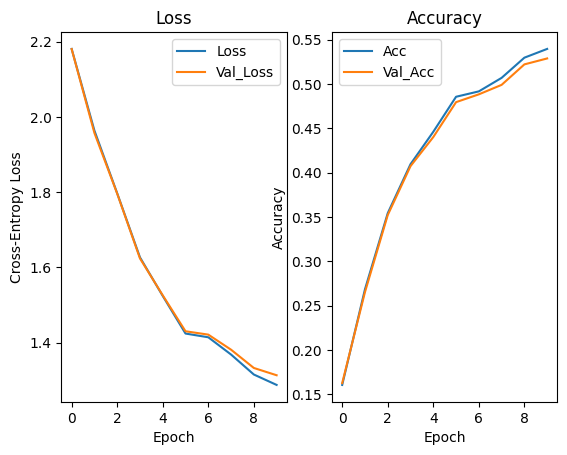

In [6]:
%matplotlib inline
onion.plot_hist(hist)
plt.show()

In [8]:
cifar_model.eval()
print(f"Training split accuracy: {cifar_model.accuracy(cifar_train_X, cifar_train_y)}")
print(f"Testing split accuracy: {cifar_model.accuracy(cifar_test_X, cifar_test_y)}")

100%|██████████| 25/25 [00:22<00:00,  1.13it/s]


Training split accuracy: 0.5374


100%|██████████| 5/5 [00:04<00:00,  1.07it/s]

Testing split accuracy: 0.5357
